In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.4/911.4 kB 23.3 MB/s eta 0:00:0000:01


In [ ]:
# 1st YoloV8 model

In [5]:
from ultralytics import YOLO
import os

# Step 1: Define Paths
BASE_DIR = '/kaggle/working/'
DATA_YAML_PATH = '/kaggle/input/plasticwaste/data.yaml'

# Step 2: Initialize YOLO Model
model = YOLO('yolov8n.pt')  

# Step 3: Train the Model
model.train(
    data=DATA_YAML_PATH,      
    epochs=1,              
    batch=32,                 # Batch size
    imgsz=320,                # Image size
    workers=8,                # Number of CPU threads for data loading
    project=os.path.join(BASE_DIR, 'YOLOv8-Project'),  # Project folder
    name='waste-detection',   # Run name
    device=0,                 # Use 'cpu' or '0' for GPU
    augment=True                    
)

# Step 4: Evaluate Model & Save Accuracy
metrics = model.val(data=DATA_YAML_PATH, split='test')

# Extract relevant metrics
accuracy = metrics.box.map50  # Mean Average Precision at 50 IoU (mAP@50)

# Store metrics in a dictionary
evaluation_results = {
    "Accuracy (mAP@50)": accuracy
}

# Display metrics
print("\n🚀 Model Evaluation Results:")
for key, value in evaluation_results.items():
    print(f"{key}: {value:.4f}")



Ultralytics 8.3.66 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/input/plasticwaste/data.yaml, epochs=1, time=None, patience=100, batch=32, imgsz=320, save=True, save_period=-1, cache=False, device=0, workers=8, project=/kaggle/working/YOLOv8-Project, name=waste-detection5, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=True, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_cr

train: Scanning /kaggle/input/plasticwaste/train/labels... 3328 images, 0 backgrounds, 48 corrupt: 100%|██████████| 3328/3328 [00:04<00:00, 819.97it/s]

train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/62a88bd71e46f62a88bd71e478_frame21_jpg.rf.c904edf1b27088d1e32a50eeddc5008f.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [      1.001]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/62a88bd71e46f62a88bd71e478_frame28_jpg.rf.392cf0d3cccaf19b7339a6bd704f0ec8.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1283      1.3288]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63175eb17be1e63175eb17be24_frame11_jpg.rf.92bcf18401d23b86d07d492228b88150.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2837      1.1835]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63175eb17be1e63175eb17be24_frame12_jpg.rf.17ff556dc5f82b87719cd2d36023d336.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2375      1.2375]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63

train: WARNING ⚠️ Cache directory /kaggle/input/plasticwaste/train is not writeable, cache not saved.
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


val: Scanning /kaggle/input/plasticwaste/valid/labels... 998 images, 0 backgrounds, 16 corrupt: 100%|██████████| 998/998 [00:01<00:00, 578.22it/s]

val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/62a88bd71e46f62a88bd71e478_frame22_jpg.rf.9e08d4490a1045eda21938aa45a52b3f.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.0006]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame10_jpg.rf.2bf0554893305c7268df665122bede24.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2899      1.1219]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame18_jpg.rf.772ed5a2fe39145996a20a3b6e6f3ec5.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1391]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame19_jpg.rf.8b899730460930752c67ae56877a60d3.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2513]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame20_j

... (11 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 20/20 [00:04<00:00,  4.13it/s]


                   all        623       1083      0.353      0.454       0.37      0.228
         Contamination         76        235      0.325      0.209      0.245      0.172
                 Glass        146        194      0.358      0.608      0.425      0.234
                 Metal        150        166      0.261      0.663      0.459      0.269
                 Paper         58         87      0.534      0.317      0.361      0.255
               Plastic        204        401      0.285      0.476      0.361      0.211


/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


Speed: 0.1ms preprocess, 2.0ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /kaggle/working/YOLOv8-Project/waste-detection52

🚀 Model Evaluation Results:
Accuracy (mAP@50): 0.3701


In [ ]:
# Save the YoloV8 model 

In [8]:
from ultralytics import YOLO
import os
import shutil

# Step 1: Define Paths
BASE_DIR = '/kaggle/working/'
DATA_YAML_PATH = '/kaggle/input/plasticwaste/data.yaml'

# Step 2: Initialize YOLO Model
model = YOLO('yolov8n.pt')  

# Step 3: Train the Model
model.train(
    data=DATA_YAML_PATH,      
    epochs=50,              
    batch=32,                 # Batch size
    imgsz=320,                # Image size
    workers=8,                # Number of CPU threads for data loading
    project=os.path.join(BASE_DIR, 'YOLOv8-Project'),  # Project folder
    name='waste-detection',   # Run name
    device=0,                 # Use 'cpu' or '0' for GPU
    augment=True                    
)

# Step 4: Evaluate Model & Save Accuracy
metrics = model.val(data=DATA_YAML_PATH, split='test')

# Extract relevant metrics
accuracy = metrics.box.map50  # Mean Average Precision at 50 IoU (mAP@50)

# Store metrics in a dictionary
evaluation_results = {
    "Accuracy (mAP@50)": accuracy
}

# Display metrics
print("\n🚀 Model Evaluation Results:")
for key, value in evaluation_results.items():
    print(f"{key}: {value:.4f}")

# Step 5: Save the Best Model
best_model_path = os.path.join(BASE_DIR, 'best_model.pt')

# Assuming that YOLO automatically saves the best model during training
# Typically, the best model is saved in the 'runs' directory (within the project folder)
best_model_src = os.path.join(BASE_DIR, 'YOLOv8-Project', 'waste-detection', 'weights', 'best.pt')

# Copy the best model to the working directory
shutil.copy(best_model_src, best_model_path)
print(f"✅ Best model saved at: {best_model_path}")


Ultralytics 8.3.66 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/input/plasticwaste/data.yaml, epochs=50, time=None, patience=100, batch=32, imgsz=320, save=True, save_period=-1, cache=False, device=0, workers=8, project=/kaggle/working/YOLOv8-Project, name=waste-detection8, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=True, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_c

train: Scanning /kaggle/input/plasticwaste/train/labels... 3328 images, 0 backgrounds, 48 corrupt: 100%|██████████| 3328/3328 [00:04<00:00, 822.72it/s]

train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/62a88bd71e46f62a88bd71e478_frame21_jpg.rf.c904edf1b27088d1e32a50eeddc5008f.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [      1.001]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/62a88bd71e46f62a88bd71e478_frame28_jpg.rf.392cf0d3cccaf19b7339a6bd704f0ec8.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1283      1.3288]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63175eb17be1e63175eb17be24_frame11_jpg.rf.92bcf18401d23b86d07d492228b88150.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2837      1.1835]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63175eb17be1e63175eb17be24_frame12_jpg.rf.17ff556dc5f82b87719cd2d36023d336.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2375      1.2375]
train: WARNING ⚠️ /kaggle/input/plasticwaste/train/images/63

train: WARNING ⚠️ Cache directory /kaggle/input/plasticwaste/train is not writeable, cache not saved.
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


val: Scanning /kaggle/input/plasticwaste/valid/labels... 998 images, 0 backgrounds, 16 corrupt: 100%|██████████| 998/998 [00:01<00:00, 551.02it/s]

val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/62a88bd71e46f62a88bd71e478_frame22_jpg.rf.9e08d4490a1045eda21938aa45a52b3f.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.0006]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame10_jpg.rf.2bf0554893305c7268df665122bede24.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2899      1.1219]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame18_jpg.rf.772ed5a2fe39145996a20a3b6e6f3ec5.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1391]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame19_jpg.rf.8b899730460930752c67ae56877a60d3.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2513]
val: WARNING ⚠️ /kaggle/input/plasticwaste/valid/images/63175eb17be1e63175eb17be24_frame20_j

... (153 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 20/20 [00:04<00:00,  4.25it/s]


                   all        623       1083      0.896      0.741      0.813      0.609
         Contamination         76        235      0.791      0.438      0.531      0.355
                 Glass        146        194      0.959      0.943      0.972      0.797
                 Metal        150        166      0.927       0.92      0.935      0.719
                 Paper         58         87      0.958      0.621      0.786      0.589
               Plastic        204        401      0.843      0.781      0.842      0.586


/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


Speed: 0.1ms preprocess, 2.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /kaggle/working/YOLOv8-Project/waste-detection82

🚀 Model Evaluation Results:
Accuracy (mAP@50): 0.8133
✅ Best model saved at: /kaggle/working/best_model.pt



image 1/1 /kaggle/input/plasticwaste/test/images/13_jpg.rf.2ec594fa3e319d6b4bb9d644722746cb.jpg: 320x320 1 Paper, 26.9ms
Speed: 1.1ms preprocess, 26.9ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)


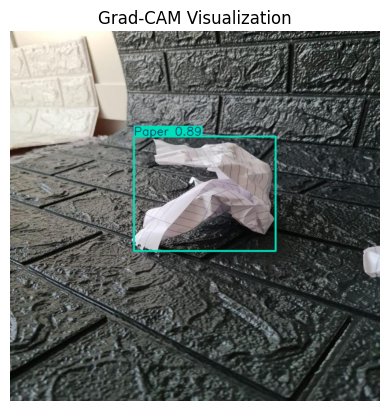


image 1/1 /kaggle/input/plasticwaste/test/images/20220216_190548_jpg.rf.c994a9d3bae84c5255248b21bf7197f6.jpg: 320x320 1 Paper, 23.7ms
Speed: 1.0ms preprocess, 23.7ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)


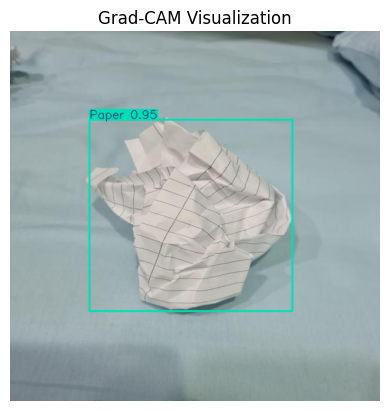


image 1/1 /kaggle/input/plasticwaste/test/images/20220216_203639_jpg.rf.01b55a249b76a3e877c6383ccec9bdb6.jpg: 320x320 1 Paper, 23.2ms
Speed: 1.0ms preprocess, 23.2ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)


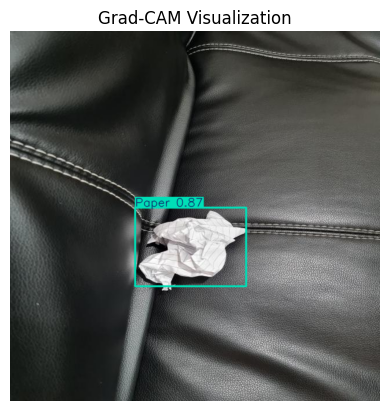


image 1/1 /kaggle/input/plasticwaste/test/images/62a3371f42f9562a3371f42f9c_frame17_jpg.rf.8ad3ffd497dcda780b0df63ac81863d4.jpg: 320x320 1 Glass, 22.5ms
Speed: 1.0ms preprocess, 22.5ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 320)


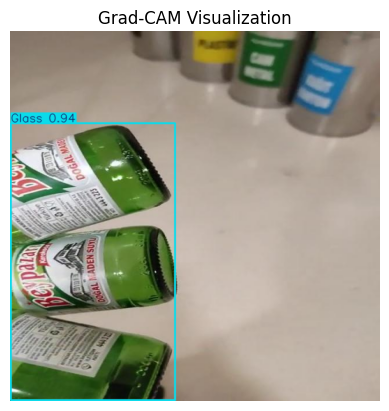


image 1/1 /kaggle/input/plasticwaste/test/images/62a74efee7f6d62a74efee7f74_frame25_jpg.rf.12add68c3c7f4b89798c7f8060d8ee51.jpg: 320x320 1 Plastic, 22.7ms
Speed: 0.9ms preprocess, 22.7ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 320)


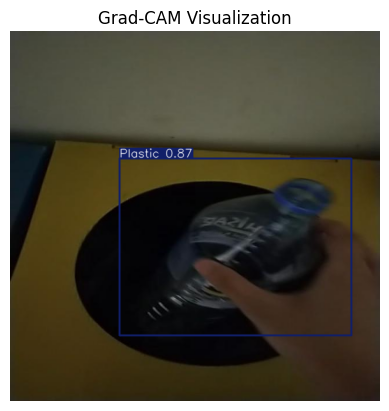

In [12]:
import matplotlib.pyplot as plt
from ultralytics import YOLO
import cv2

def generate_gradcam(model, image_path):
    # Perform inference
    results = model(image_path)

    # Access Grad-CAM visualization from results (if supported)
    if hasattr(results[0], 'plot'):
        gradcam_image = results[0].plot()
    else:
        raise AttributeError("The 'Results' object does not support Grad-CAM visualization. Please check the library documentation or update your code.")

    # Display Grad-CAM output
    plt.imshow(cv2.cvtColor(gradcam_image, cv2.COLOR_BGR2RGB))
    plt.title("Grad-CAM Visualization")
    plt.axis("off")
    plt.show()

# Example usage
test_image_path = '/kaggle/input/plasticwaste/test/images/13_jpg.rf.2ec594fa3e319d6b4bb9d644722746cb.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path)

test_image_path1 = '/kaggle/input/plasticwaste/test/images/20220216_190548_jpg.rf.c994a9d3bae84c5255248b21bf7197f6.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path1)

test_image_path2 = '/kaggle/input/plasticwaste/test/images/20220216_203639_jpg.rf.01b55a249b76a3e877c6383ccec9bdb6.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path2)

test_image_path3 = '/kaggle/input/plasticwaste/test/images/62a3371f42f9562a3371f42f9c_frame17_jpg.rf.8ad3ffd497dcda780b0df63ac81863d4.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path3)

test_image_path4 = '/kaggle/input/plasticwaste/test/images/62a74efee7f6d62a74efee7f74_frame25_jpg.rf.12add68c3c7f4b89798c7f8060d8ee51.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path4)



image 1/1 /kaggle/input/plasticwaste/test/images/62ac3ee0d10b362ac3ee0d10ba_frame12_jpg.rf.217866dcf63d36d3553d7bb81efd42b9.jpg: 320x320 1 Plastic, 28.4ms
Speed: 1.4ms preprocess, 28.4ms inference, 1.4ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=4, Confidence=0.8933, BBox=[121.32054138183594, 158.45181274414062, 394.54791259765625, 372.0623474121094]


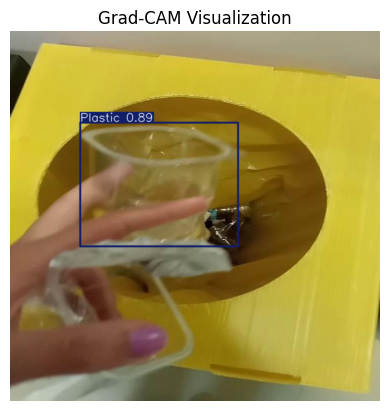


image 1/1 /kaggle/input/plasticwaste/test/images/62a74efee7f6d62a74efee7f74_frame22_jpg.rf.627073c01fc4fb17f54ff6a355c173d5.jpg: 320x320 1 Plastic, 23.2ms
Speed: 1.0ms preprocess, 23.2ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=4, Confidence=0.8607, BBox=[172.4122314453125, 217.9033203125, 639.3562622070312, 562.049072265625]


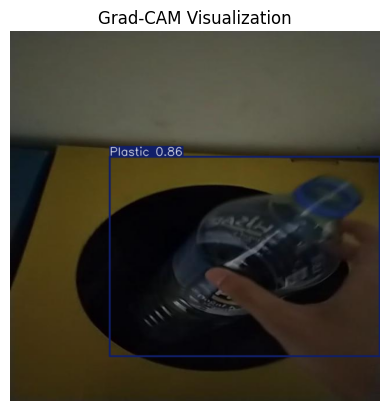


image 1/1 /kaggle/input/plasticwaste/test/images/62ab2cba6d6fa62ab2cba6d701_frame20_jpg.rf.2a5b9d6c6210f512f372039305d2ccbf.jpg: 320x320 1 Plastic, 24.5ms
Speed: 1.0ms preprocess, 24.5ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=4, Confidence=0.8442, BBox=[95.05243682861328, 329.7899169921875, 338.54541015625, 465.8505859375]


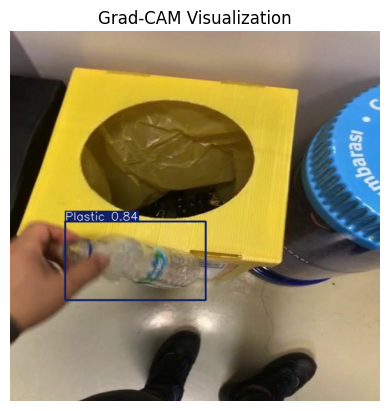


image 1/1 /kaggle/input/plasticwaste/test/images/62a88bd71e46f62a88bd71e478_frame12_jpg.rf.fbd02c7cd83826643022a241d7dc0618.jpg: 320x320 2 Plastics, 24.0ms
Speed: 1.0ms preprocess, 24.0ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=4, Confidence=0.9272, BBox=[117.01434326171875, 2.56036376953125, 639.7854614257812, 638.5302734375]


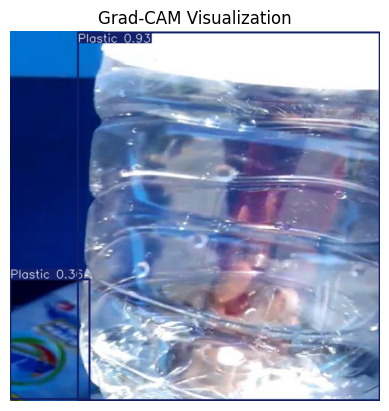


image 1/1 /kaggle/input/plasticwaste/test/images/62b0acf7591de62b0acf7591e7_frame32_jpg.rf.2fcbf464889e0d27a1640e627ff8a7c7.jpg: 320x320 1 Metal, 24.3ms
Speed: 1.0ms preprocess, 24.3ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=2, Confidence=0.9597, BBox=[323.00579833984375, 364.4054260253906, 419.1080322265625, 452.3137512207031]


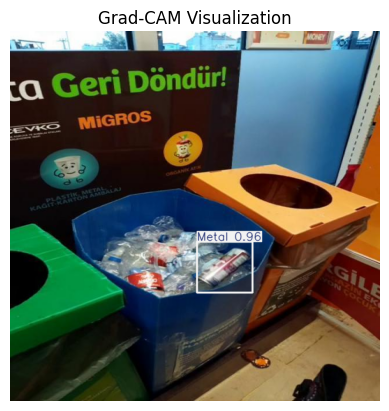


image 1/1 /kaggle/input/plasticwaste/test/images/62b5c68b8a86362b5c68b8a867_frame17_jpg.rf.5bb6ca26e02726d4e268afa5702f819b.jpg: 320x320 1 Metal, 24.0ms
Speed: 1.0ms preprocess, 24.0ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class ID=2, Confidence=0.9135, BBox=[153.624267578125, 268.31634521484375, 357.0319519042969, 505.27203369140625]


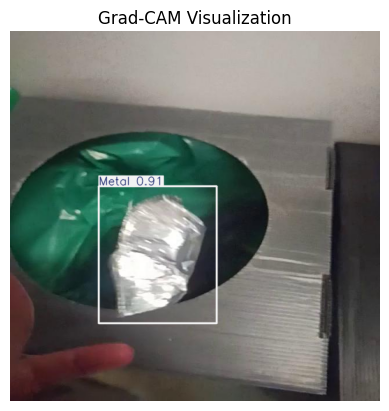

In [13]:
import matplotlib.pyplot as plt
from ultralytics import YOLO
import cv2

def generate_gradcam(model, image_path):
    # Perform inference
    results = model(image_path)

    # Extract detections
    if results and hasattr(results[0], 'boxes'):
        boxes = results[0].boxes  # Bounding box information
        if boxes.conf is not None and len(boxes.conf) > 0:
            best_idx = boxes.conf.argmax()  # Find index of the highest confidence
            best_box = boxes[best_idx]  # Get best detection
            
            # Extract information
            best_conf = boxes.conf[best_idx].item()
            best_cls = int(boxes.cls[best_idx].item()) if boxes.cls is not None else "Unknown"
            best_xyxy = boxes.xyxy[best_idx].tolist()  # Bounding box coordinates
            
            print(f"Best Detection: Class ID={best_cls}, Confidence={best_conf:.4f}, BBox={best_xyxy}")

    # Access Grad-CAM visualization (if supported)
    if hasattr(results[0], 'plot'):
        gradcam_image = results[0].plot()
        plt.imshow(cv2.cvtColor(gradcam_image, cv2.COLOR_BGR2RGB))
        plt.title("Grad-CAM Visualization")
        plt.axis("off")
        plt.show()
    else:
        raise AttributeError("The 'Results' object does not support Grad-CAM visualization.")



# Example usage
test_image_path = '/kaggle/input/plasticwaste/test/images/62ac3ee0d10b362ac3ee0d10ba_frame12_jpg.rf.217866dcf63d36d3553d7bb81efd42b9.jpg'
generate_gradcam(model, test_image_path)

test_image_path5 = '/kaggle/input/plasticwaste/test/images/62a74efee7f6d62a74efee7f74_frame22_jpg.rf.627073c01fc4fb17f54ff6a355c173d5.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path5)

test_image_path1 = '/kaggle/input/plasticwaste/test/images/62ab2cba6d6fa62ab2cba6d701_frame20_jpg.rf.2a5b9d6c6210f512f372039305d2ccbf.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path1)

test_image_path2 = '/kaggle/input/plasticwaste/test/images/62a88bd71e46f62a88bd71e478_frame12_jpg.rf.fbd02c7cd83826643022a241d7dc0618.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path2)

test_image_path3 = '/kaggle/input/plasticwaste/test/images/62b0acf7591de62b0acf7591e7_frame32_jpg.rf.2fcbf464889e0d27a1640e627ff8a7c7.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path3)

test_image_path4 = '/kaggle/input/plasticwaste/test/images/62b5c68b8a86362b5c68b8a867_frame17_jpg.rf.5bb6ca26e02726d4e268afa5702f819b.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path4)



image 1/1 /kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame47_jpg.rf.2ec94dbaf6164a6794272270a07299dc.jpg: 320x320 1 Metal, 25.3ms
Speed: 1.4ms preprocess, 25.3ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Metal, Confidence=0.8846, BBox=[177.05422973632812, 217.86160278320312, 403.5428161621094, 473.4764099121094]


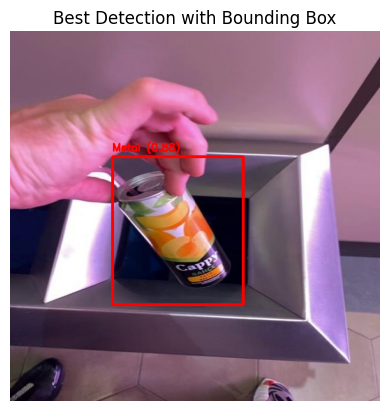


image 1/1 /kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame32_jpg.rf.59a35b7ac2e8d80a1c535130fde5c7f8.jpg: 320x320 1 Metal, 23.0ms
Speed: 1.0ms preprocess, 23.0ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Metal, Confidence=0.8927, BBox=[157.86257934570312, 216.00697326660156, 424.3050231933594, 467.776123046875]


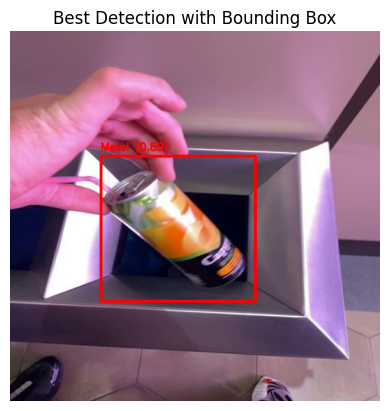


image 1/1 /kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame36_jpg.rf.144775d81af67552f4469392b0ba6277.jpg: 320x320 1 Metal, 24.1ms
Speed: 1.0ms preprocess, 24.1ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Metal, Confidence=0.9075, BBox=[223.90643310546875, 217.98077392578125, 484.6715087890625, 469.0335693359375]


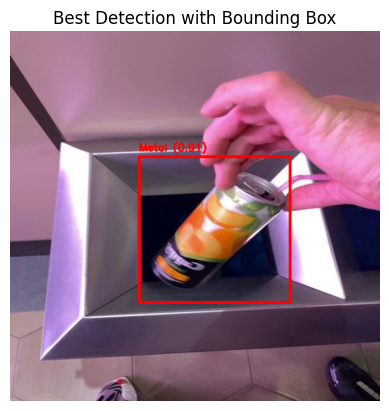


image 1/1 /kaggle/input/plasticwaste/test/images/62c1715b8961562c1715b8961a_frame6_jpg.rf.e84b9b24e02b3d1855cbcc6074d2391f.jpg: 320x320 1 Plastic, 23.3ms
Speed: 1.0ms preprocess, 23.3ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Plastic, Confidence=0.9287, BBox=[65.07254028320312, 282.59796142578125, 337.3459167480469, 485.924560546875]


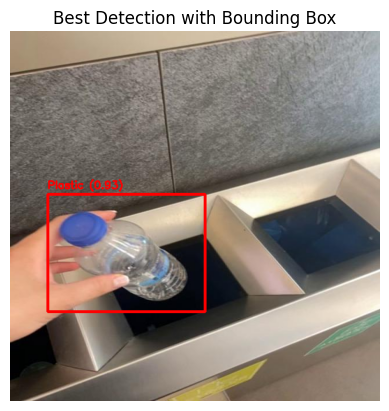


image 1/1 /kaggle/input/plasticwaste/test/images/62c5233f597e562c5233f597fb_frame58_jpg.rf.7c4bc8e120310ea9c5df57fa06655526.jpg: 320x320 1 Glass, 23.3ms
Speed: 1.0ms preprocess, 23.3ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Glass, Confidence=0.9496, BBox=[0.0, 45.88090515136719, 450.29022216796875, 358.64617919921875]


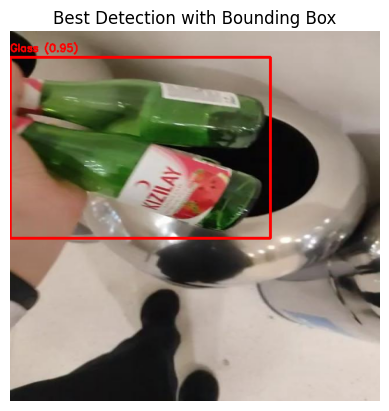


image 1/1 /kaggle/input/plasticwaste/test/images/62c692e42087e62c692e420884_frame5_jpg.rf.fc79c8d2f1c687e3443a59d3d0d4dffe.jpg: 320x320 1 Metal, 23.0ms
Speed: 1.0ms preprocess, 23.0ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Metal, Confidence=0.9070, BBox=[220.61907958984375, 264.4712829589844, 515.4009399414062, 363.9563903808594]


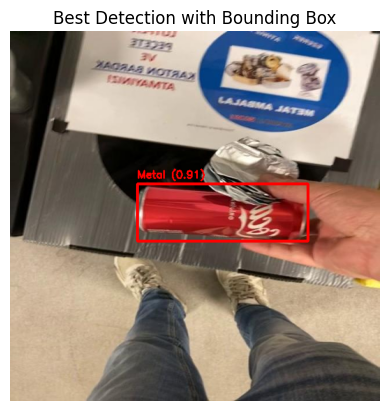


image 1/1 /kaggle/input/plasticwaste/test/images/62d66e7807ebd62d66e7807ec6_frame41_jpg.rf.124cab5792b14984e926dbf4bbf41fc7.jpg: 320x320 3 Plastics, 23.9ms
Speed: 1.1ms preprocess, 23.9ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Best Detection: Class=Plastic, Confidence=0.7868, BBox=[13.37261962890625, 231.48385620117188, 240.4156494140625, 465.0344543457031]


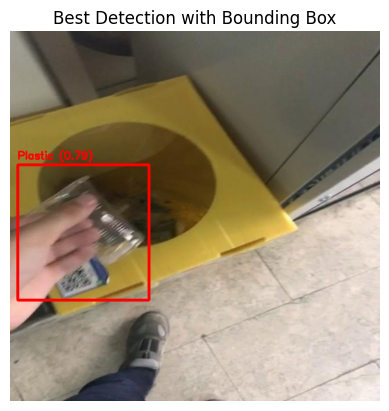

In [14]:
import matplotlib.pyplot as plt
from ultralytics import YOLO
import cv2


# Define class names (COCO dataset for YOLOv8n by default)
CLASS_NAMES = model.names  # Get class names from the model

def generate_gradcam(model, image_path):
    # Perform inference
    results = model(image_path)

    # Read the original image
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for display

    # Extract detections
    if results and hasattr(results[0], 'boxes'):
        boxes = results[0].boxes  # Bounding box information
        if boxes.conf is not None and len(boxes.conf) > 0:
            best_idx = boxes.conf.argmax()  # Find index of the highest confidence
            best_box = boxes[best_idx]  # Get best detection
            
            # Extract information
            best_conf = boxes.conf[best_idx].item()
            best_cls = int(boxes.cls[best_idx].item()) if boxes.cls is not None else "Unknown"
            best_xyxy = boxes.xyxy[best_idx].tolist()  # Bounding box coordinates
            best_class_name = CLASS_NAMES.get(best_cls, "Unknown")  # Get class name
            
            print(f"Best Detection: Class={best_class_name}, Confidence={best_conf:.4f}, BBox={best_xyxy}")

            # Draw bounding box on the image
            x1, y1, x2, y2 = map(int, best_xyxy)
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 3)  # Blue box
            
            # Add class name and confidence on the bounding box
            label = f"{best_class_name} ({best_conf:.2f})"
            cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 
                        0.6, (255, 0, 0), 2)

    # Display the image with the best detection
    plt.imshow(image)
    plt.title("Best Detection with Bounding Box")
    plt.axis("off")
    plt.show()


# Example usage
test_image_path = '/kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame47_jpg.rf.2ec94dbaf6164a6794272270a07299dc.jpg'
generate_gradcam(model, test_image_path)

test_image_path6 = '/kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame32_jpg.rf.59a35b7ac2e8d80a1c535130fde5c7f8.jpg'
generate_gradcam(model, test_image_path6)

test_image_path5 = '/kaggle/input/plasticwaste/test/images/62bf296b26d2162bf296b26d27_frame36_jpg.rf.144775d81af67552f4469392b0ba6277.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path5)

test_image_path1 = '/kaggle/input/plasticwaste/test/images/62c1715b8961562c1715b8961a_frame6_jpg.rf.e84b9b24e02b3d1855cbcc6074d2391f.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path1)

test_image_path2 = '/kaggle/input/plasticwaste/test/images/62c5233f597e562c5233f597fb_frame58_jpg.rf.7c4bc8e120310ea9c5df57fa06655526.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path2)

test_image_path3 = '/kaggle/input/plasticwaste/test/images/62c692e42087e62c692e420884_frame5_jpg.rf.fc79c8d2f1c687e3443a59d3d0d4dffe.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path3)

test_image_path4 = '/kaggle/input/plasticwaste/test/images/62d66e7807ebd62d66e7807ec6_frame41_jpg.rf.124cab5792b14984e926dbf4bbf41fc7.jpg'  # Replace with actual test image path
generate_gradcam(model, test_image_path4)